# Классификация транзакций и логирование экспериментов

### Общая информация 
Компания TechGadget — международный ретейлер. 
Последнее время резко возрасло число транзакций, что предположительно вызвано фродом (мошенничеством).

Чтобы выявлять фрод в транзакциях разрабатывается **ML модель классификации**.
Перед построением модели необходимо провести ИАД, исследовать распределение мошенничества по различным географическим регионам и устройствам интернет-заказов.
Необходимо проверить несколько гипотез о мошенничестве.

Для прослеживаемости экспериментов и масштабирования решения предлагается использовать **MLflow**.

### Цель

- построить модель классификации транзакций для выявления мошенничества и залогировать все артефакты с помощью **MLflow**

### Задачи

- Разработать модель классификации транзакций (`fraud_flag = 1`) на основе данных о платежах, поведении клиентов и признаках риска.
- Интегрировать MLflow для трекинга экспериментов: логирования метрик, гиперпараметров и артефактов (самой модели, графиков и данных).
- Обеспечить возможность переобучения модели с фиксацией версий и сравнением результатов в **MLflow**.
- Подготовить модель к развёртыванию в продакшене, зарегистрировав её в **Model Registry**.

### Данные

Данные описывают поведенческие паттерны клиентов, их транзакционную активность и различные индикаторы, которые помогают выявлять подозрительные действия.

Датасет: 
- https://code.s3.yandex.net/datasets/retail_fraud_detection_100k.csv




---


## 0. Настройка проекта

In [1]:
import mlflow
import os
from copy import deepcopy
from dotenv import load_dotenv
import pandas as pd
import shap
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from typing import Optional
from scipy.stats import chi2_contingency
from phik import phik_matrix
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score, RocCurveDisplay
from sklearn.metrics import recall_score, f1_score, confusion_matrix

load_dotenv()

True

In [2]:
# воспроизводимость  вычислений
RANDOM_SEED = 42 
# настройки визуалиции 
plt.rcParams["figure.figsize"] = (12, 8)

In [3]:
# путь для скачивание данных
data_path = 'https://code.s3.yandex.net/datasets/retail_fraud_detection_100k.csv'

## 1. Чтение данных


In [4]:
df = pd.read_csv(data_path)

display(df.info(), df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   transaction_id                    100000 non-null  object 
 1   customer_id                       100000 non-null  object 
 2   transaction_timestamp             100000 non-null  object 
 3   transaction_amount                100000 non-null  float64
 4   payment_method                    100000 non-null  object 
 5   device_type                       100000 non-null  object 
 6   location                          100000 non-null  object 
 7   merchant_category                 100000 non-null  object 
 8   is_international                  100000 non-null  int64  
 9   transaction_frequency_24h         100000 non-null  int64  
 10  avg_transaction_amount_7d         100000 non-null  float64
 11  failed_transaction_count_24h      100000 non-null  in

None

,transaction_id,customer_id,transaction_timestamp,transaction_amount,payment_method,device_type,location,merchant_category,is_international,transaction_frequency_24h,...,failed_transaction_count_24h,account_age_days,previous_fraud_flag,unusual_amount_flag,unusual_location_flag,multiple_transactions_short_time,high_risk_device_flag,velocity_flag,fraud_flag,fraud_risk
0,T0000001,C20953,2026-03-04 19:56:23.679173,56.31,Debit Card,Tablet,Canada,Fashion,0,13,...,4,1054,0,0,0,1,0,1,0,Medium
1,T0000002,C24133,2026-03-09 19:56:23.679330,20.35,Credit Card,Tablet,India,Electronics,0,3,...,2,97,0,0,0,0,0,0,0,Low
2,T0000003,C07165,2026-01-01 19:56:23.679362,48.72,Debit Card,Tablet,UK,Travel,0,8,...,4,779,1,0,0,0,0,0,0,Medium
3,T0000004,C19310,2025-12-09 19:56:23.679385,153.62,Debit Card,Mobile,Australia,Fashion,0,14,...,3,286,1,1,0,1,0,1,1,High
4,T0000005,C25019,2025-11-09 19:56:23.679409,115.32,PayPal,Mobile,India,Gaming,0,10,...,3,866,0,0,0,1,0,0,0,Low


**Анализ**

Преобразования:
- transaction_timestamp - необходимо перевести время в datetime
- можно уменьшить объем занимаемой памяти: int64-ы редуцировать для булевых флагов

Датасет по объему и описанию совпадает с заявленным:
- 10к объектов
- 20 признаков + таргет(флаг фрода)

## 2. Анализ и исследование данных


    Все графики, построенные в ходе анализа, обязательно залогируйте в запуск эксперимента в MLflow — это поможет визуально сохранить логику решения задачи.

In [5]:
# определение категориальных и числовых типов
CAT_COLS_TYPES = ['object', 'category', np.datetime64]
NUM_COLS_TYPES = [np.number]

In [6]:
def get_cat_num_cols(df: pd.DataFrame) -> tuple[list[str], list[str]]:
    """Получить списки названий категориальных и числовых столбцов"""
    cat_cols = df.select_dtypes(include=CAT_COLS_TYPES).columns.tolist()
    num_cols = df.select_dtypes(include=NUM_COLS_TYPES).columns.tolist()

    return cat_cols, num_cols

def get_base_df_info(name: str, df: pd.DataFrame):
    """Информация о датафрейме для ИАД анализа"""
    
    rows_count, cols_count = df.shape
    missing = df.isna().sum()
    missing_share = (missing / rows_count * 100).round(2) if rows_count else pd.Series(0, index=df.columns, dtype=float)
    duplicates_count = (df.duplicated().sum() / rows_count * 100).round(2)
    unique_values = df.nunique(dropna=False)

    cat_cols, num_cols = get_cat_num_cols(df=df)

    overview_df = pd.DataFrame({
        'Метрика': ['Строк', 'Колонок', 'Явных дубликатов, %', 'Категориальных колонок', 'Числовых колонок'],
        'Значение': [rows_count, cols_count, duplicates_count, int(len(cat_cols)), int(len(num_cols))],
    })

    summary_df = pd.DataFrame({
        'Тип данных': df.dtypes.astype(str),
        'Пропуски': missing,
        'Доля пропусков, %': missing_share,
        'Уникальные значения': unique_values,
    }).sort_values(by=['Пропуски', 'Уникальные значения'], ascending=[False, False])

    cols_df = pd.DataFrame({
        'Категориальные колонки': pd.Series(cat_cols),
        'Числовые колонки': pd.Series(num_cols),
    })

    print(f'Общая информация о датафрейме {name}')
    display(df.head())
    display(overview_df)

    print('Сводка по признакам')
    display(summary_df)

    print('Типы колонок')
    display(cols_df)
    print('-'*50)

In [7]:
get_base_df_info(name='Clients Dataset', df=df)

Общая информация о датафрейме Clients Dataset


,transaction_id,customer_id,transaction_timestamp,transaction_amount,payment_method,device_type,location,merchant_category,is_international,transaction_frequency_24h,...,failed_transaction_count_24h,account_age_days,previous_fraud_flag,unusual_amount_flag,unusual_location_flag,multiple_transactions_short_time,high_risk_device_flag,velocity_flag,fraud_flag,fraud_risk
0,T0000001,C20953,2026-03-04 19:56:23.679173,56.31,Debit Card,Tablet,Canada,Fashion,0,13,...,4,1054,0,0,0,1,0,1,0,Medium
1,T0000002,C24133,2026-03-09 19:56:23.679330,20.35,Credit Card,Tablet,India,Electronics,0,3,...,2,97,0,0,0,0,0,0,0,Low
2,T0000003,C07165,2026-01-01 19:56:23.679362,48.72,Debit Card,Tablet,UK,Travel,0,8,...,4,779,1,0,0,0,0,0,0,Medium
3,T0000004,C19310,2025-12-09 19:56:23.679385,153.62,Debit Card,Mobile,Australia,Fashion,0,14,...,3,286,1,1,0,1,0,1,1,High
4,T0000005,C25019,2025-11-09 19:56:23.679409,115.32,PayPal,Mobile,India,Gaming,0,10,...,3,866,0,0,0,1,0,0,0,Low


,Метрика,Значение
0,Строк,100000.0
1,Колонок,21.0
2,"Явных дубликатов, %",0.0
3,Категориальных колонок,8.0
4,Числовых колонок,13.0


Сводка по признакам


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
transaction_id,object,0,0.0,100000
transaction_timestamp,object,0,0.0,100000
transaction_amount,float64,0,0.0,32371
customer_id,object,0,0.0,28955
avg_transaction_amount_7d,float64,0,0.0,17927
account_age_days,int64,0,0.0,1990
transaction_frequency_24h,int64,0,0.0,14
location,object,0,0.0,6
merchant_category,object,0,0.0,6
payment_method,object,0,0.0,5


Типы колонок


,Категориальные колонки,Числовые колонки
0,transaction_id,transaction_amount
1,customer_id,is_international
2,transaction_timestamp,transaction_frequency_24h
3,payment_method,avg_transaction_amount_7d
4,device_type,failed_transaction_count_24h
5,location,account_age_days
6,merchant_category,previous_fraud_flag
7,fraud_risk,unusual_amount_flag
8,NaN,unusual_location_flag
9,NaN,multiple_transactions_short_time


--------------------------------------------------


Анализ:
- явных дублей нет, пропусков нет
- все transaction_id уникальные

### Преобразование временных колонок

In [8]:
df['transaction_timestamp_dt'] = pd.to_datetime(df['transaction_timestamp'])
df['transaction_timestamp_dow'] = pd.to_datetime(df['transaction_timestamp']).dt.dayofweek
df['transaction_timestamp_h'] = pd.to_datetime(df['transaction_timestamp']).dt.hour
df = df.drop(columns=['transaction_timestamp'])

### Анализ распределений

In [9]:
cat_cols_names, num_cols_names = get_cat_num_cols(df=df)

In [10]:
extra_cols = ['transaction_id', 'customer_id', 'transaction_timestamp_dt']

cat_cols_names_no_id = [name for name in cat_cols_names if name not in extra_cols]

Категориальные признаки

In [11]:
def plot_count_bars(
    df: pd.DataFrame, col_name: str,
    show_mean: bool = False
):
    """Столбчатые диаграммы распрелелений категориальных признаков"""
    counts = df[col_name].value_counts()
    freq_order = counts.index
    mean_value = counts.mean()

    ax = sns.countplot(data=df, x=col_name, order=freq_order)

    if show_mean:
        # горизонтальная линия среднего значения
        plt.axhline(
            y=mean_value,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Среднее: {mean_value:.1f}",
        )
        plt.legend()

    plt.title(f"Распределение {col_name}")
    plt.ylabel("количество")
    plt.xticks(rotation=45)


    plt.ylim(top=plt.ylim()[1] * 1.05)

    plt.show()

In [12]:
# for name in cat_cols_names_no_id:
#     plot_count_bars(df=df, col_name=name)

анализ:
- распределение в 'payment_method', 'device_type', 'location', 'merchant_category' по категориям равномерное
- по fraud_risk кол-во Medium > Low > High - в целом закономерно, что преобладает средний риск мошенничества

Количественные признаки

In [13]:
def plot_hist_box(
    df: pd.DataFrame, 
    feature_name: str,
    x_label: str = 'значение',
    bins=30,
    hue: Optional[str]=None
):
    """Гистограмма + ящик с усами для анализа распределений количественных данных"""
    fig, axes = plt.subplots(nrows=2, ncols=1)
    axes[0].grid(True)
    axes[1].grid(True)
    sns.histplot(data=df, x=feature_name, stat='density', ax=axes[0], bins=bins, hue=hue, legend=True)
    
    plt.figtext(
        0.75,0.4, 
        df[feature_name].describe().to_string(), 
        fontsize=10,
        family="monospace",  # Ensures perfect columns alignment
        verticalalignment="center",
        bbox=dict(boxstyle="square,pad=0.6", facecolor="#f8f9fa", edgecolor="gray"),
    )

    sns.boxplot(data=df, x=feature_name, orient="h", ax=axes[1])
    axes[0].set_title(f'Распределение {feature_name}')
    axes[0].set_ylabel('плотность')
    axes[1].set_xlabel(x_label)
    axes[1].set_ylabel(feature_name)
    plt.show()

In [14]:
# for name in num_cols_names:
#     plot_hist_box(df=df, feature_name=name)

Анализ:
- распределение по transaction_amout содержит выбросы (экстремально большие транзакции).
- к часовым признакам стоит применить $\cos( x \cdot \frac{2 \pi}{24})$ преобразование, чтобы учесть цикличность 
- дисбаланса в таргете **fraud_flag** нет
- наблюдается дисбаланс в **unusual_amout_flag** и **high_risk_device_flag**: кол-во 0 >> кол-во 1
- признак transaction_timestamp_h = const - бесполезен и можно удалить

**Исследование таргета**

In [15]:
target_col = 'fraud_flag'

In [16]:
# plot_count_bars(df=df, col_name=target_col)

Анализ:
- дисбаланса нет

**Категориальные признаки**

In [17]:
# for name in cat_cols_names_no_id:
#     plot_hist_box(df=df, feature_name=name, hue=target_col)

**Анализ:**
- `device_type` - для Mobile доля мошенничества выше, чем обычных транзакций. Для остальных категорий наоборот
- `fraud_risk` - для High - ~100% фрод, для Low ~100% не фрод, для Medium соотношение 2/3.
- среди осальных признаков распределение таргета равномерное 

**Количественные признаки**

In [18]:
# for name in num_cols_names:
#     plot_hist_box(df=df, feature_name=name, hue=target_col)

Анализ:

- transaction_amount - чем выше суммы, тем больше доля фрода
- is_international - в международных транзакцииях больше доля фрода 
- transactional_freq - [8, 14]h - доля фрода повышена
- avg_transaction_amount_7d - при значениях менее 75 доля фрода выше
- failed_transaction_count_24h - 1,2 - доли равны, 3-4 доля фрода выше
- previous_fraud_flag - доля выше, если до этого был фрод 
- unusial_amount, unusial_location, multiple_transactions_short_time, high_risk_device_flag, velocity_flag - доля фрода больше при 1
- по дням недели мошенничество распределено одинаково - видимой связи нет

### Проверка стат. гипотез

Использование критерия Хи-квадрат Пирсона

Гипотезы:
- Фрод чаще встречается среди международных транзакций.
- Мошеннические операции чаще проходят через одни и те же методы оплаты.
- Мошенничество чаще происходит в определённые дни недели.
- Для фрода чаще используются высокорисковые устройства.

In [19]:
# порог значимости стат. тестов
alpha = 0.05

# категориальные признаки для проверки
features_to_check = ['is_international', 'payment_method', 'transaction_timestamp_dow', 'high_risk_device_flag']
target_col_name = 'fraud_flag'

In [20]:
def chi_square_test(
    feature_name: str,
    feature_series: pd.Series, 
    target_series: pd.Series, 
    alpha: float
):
    """Критерий Хи-квадрат Пирсона для проверки гипотезы"""
    # таблица сопряженности

    contingency_table = pd.crosstab(feature_series, target_series)
    stat_test_res = chi2_contingency(contingency_table)
    p_value = round(stat_test_res.pvalue, 5)
    
    print('-'*50)
    print(f'Признак: {feature_name}')
    if p_value <= alpha:
         print(f'Нулевая гипотеза отвергается: {p_value=} <= {alpha=}')
    else:
        print(f'Нет оснований отвергать нулевую гипотезу {p_value=} > {alpha}')

In [21]:
for name in features_to_check:
    chi_square_test(
        feature_name=name,
        feature_series=df[name],
        target_series=df[target_col_name],
        alpha=alpha,
    )

--------------------------------------------------
Признак: is_international
Нулевая гипотеза отвергается: p_value=np.float64(0.0) <= alpha=0.05
--------------------------------------------------
Признак: payment_method
Нет оснований отвергать нулевую гипотезу p_value=np.float64(0.87833) > 0.05
--------------------------------------------------
Признак: transaction_timestamp_dow
Нет оснований отвергать нулевую гипотезу p_value=np.float64(0.34763) > 0.05
--------------------------------------------------
Признак: high_risk_device_flag
Нулевая гипотеза отвергается: p_value=np.float64(0.0) <= alpha=0.05


**Анализ**

**Подтвержденные** гипотезы:
- Фрод чаще встречается среди международных транзакций.
- Для фрода чаще используются высокорисковые устройства

Гипотезы, которые **не подтвердились**:
- Мошеннические операции чаще проходят через одни и те же методы оплаты.
- Мошенничество чаще происходит в определённые дни недели.


### Корреляционный анализ

In [22]:
def get_corr_matrix(
    data: pd.DataFrame, feat_cols: list[str], 
    num_cols: list[str]
):
    """Матрица корреляций"""
    corr_matrix = data[feat_cols].phik_matrix(
        interval_cols=num_cols if len(num_cols) > 0 else None,
        njobs=-1,
    )

    return corr_matrix

def plot_corr_matrix(corr_matrix):
    """Тепловая карта"""

    sns.heatmap(data=corr_matrix, annot=True, fmt='.2f', linewidths=0.5, cmap='viridis')

    plt.title('Тепловая карта матрицы корреляций')
    plt.show()

def corr_with_target(corr_matrix, target_col_name):
    """Корреляция с таргетом"""
    return corr_matrix[target_col_name].sort_values(ascending=False)

In [23]:
cat_cols_feat, num_cols_names = get_cat_num_cols(df=df)

In [24]:
cat_cols_feat_corr = [name for name in cat_cols_names if name not in ['transaction_id', 'customer_id', 'transaction_timestamp_dt']]
num_cols_names_corr = [name for name in num_cols_names if name != target_col_name]

In [25]:
corr_matrix = get_corr_matrix(
    data=df, 
    feat_cols=cat_cols_feat_corr + num_cols_names_corr + [target_col_name], 
    num_cols=num_cols_names_corr + [target_col_name]
)

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.10/site-packages/phik/data_quality.py:72: UserWarning: Not enough unique value for variable transaction_timestamp_h for analysis 1. Dropping this column
  warnings.warn(


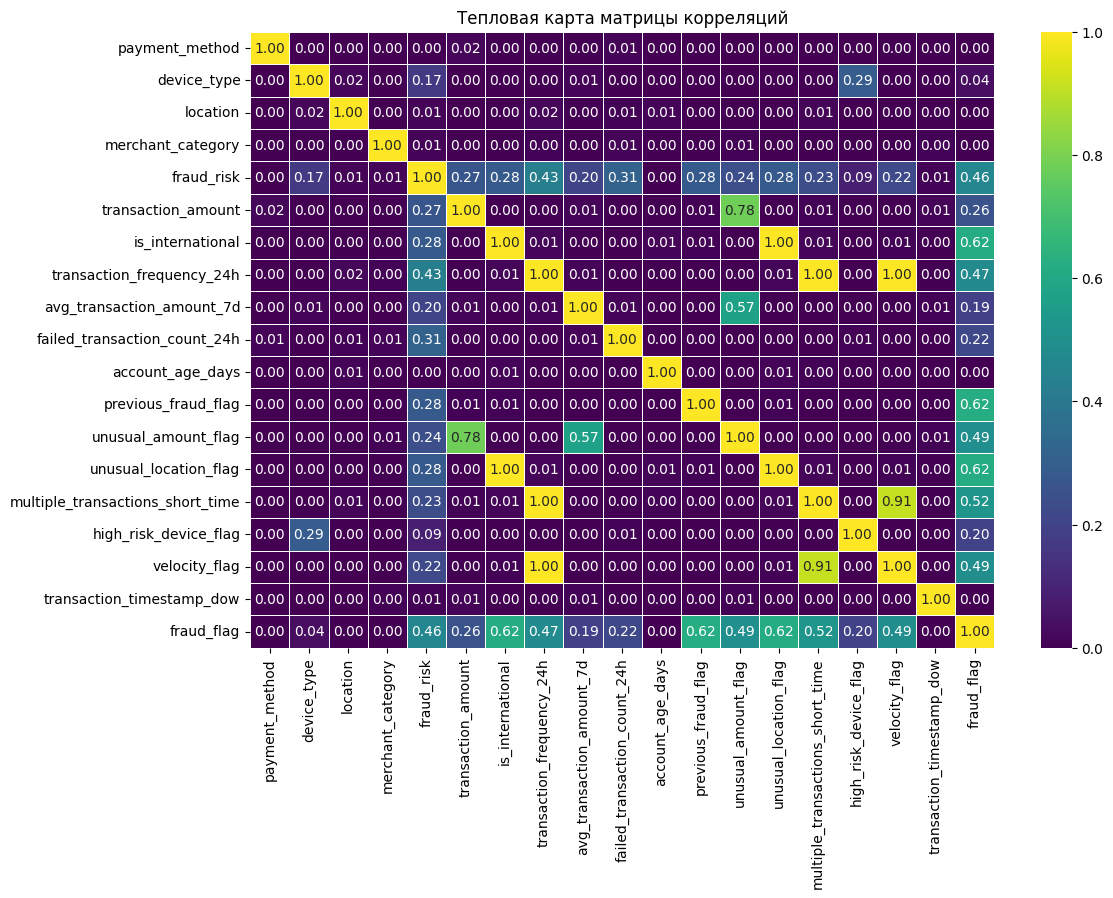

In [26]:
plot_corr_matrix(corr_matrix)

**Анализ:**
- есть сильно скоррелированные признаки (corr = 1): 
    - corr(velocity_flag, 'transaction_frequency_24h') = 1, 
    - corr(multiple_transactions_short_time, transaction_frequency_24h) = 1,
    - corr(unusual_location_flag, is_international) = 1

В пайплайне предобработки данных стоит отсекать один из пары скоррелированных признаков, чтобы модель работала более стабильно


## 3. Предобработка данных

Обработайте пропущенные значения, если они обнаружатся: удалите строки или заполните пропуски средним, медианой, модой — в зависимости от контекста.
Убедитесь, что transaction_timestamp переведён в формат datetime , а категориальные признаки закодированы с помощью One-Hot Encoding.
Если это необходимо, нормализуйте числовые признаки, не затрагивая колонки с флагами.
Разделите данные на обучающую и тестовую выборки.

In [27]:
# преобразование типов
cat_cols, _ = get_cat_num_cols(df=df)
for col in cat_cols:
    # приведение всех категориальных признаков к pd.categorical
    df[col] = df[col].astype('category')

In [28]:
# сортировка по времени
df = df.sort_values(by='transaction_timestamp_dt').reset_index(drop=True)

### Чистка данных 

In [29]:
# Признаки для удаления
cols_to_del = [
    'transaction_id', # бесполезные уникальные значения транзакций
    'transaction_timestamp_h', # константное значение
    'fraud_risk',  # слив таргета 
    'customer_id', # слив таргета 
    'transaction_timestamp_dt', # бесполезно
]


In [30]:
df_prep = df.drop(columns=cols_to_del)

### Разделение на выборки

In [31]:
X = df_prep.drop(columns='fraud_flag')
y = pd.Series(df_prep['fraud_flag'], name='target')
display(X.shape, y.shape)

(100000, 17)

(100000,)

In [32]:
# train_val 80% и test 20%
train_val_size = 0.8
ds_len = X.shape[0]
train_val_idx = int(ds_len*train_val_size)

X_train_val = X.iloc[:train_val_idx]
X_test = X.iloc[train_val_idx:]

y_train_val = y.iloc[:train_val_idx]
y_test = y.iloc[train_val_idx:]


# train 60% и val 20%
train_size = 0.75
ds_len = X_train_val.shape[0]
train_idx = int(ds_len*train_size)

X_train = X_train_val.iloc[:train_idx]
X_val = X_train_val.iloc[train_idx:]

y_train = y_train_val.iloc[:train_idx]
y_val = y_train_val.iloc[train_idx:]

In [33]:
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape

((60000, 17), (20000, 17), (20000, 17), (60000,), (20000,), (20000,))

## 4. MLflow: Настройка и трекинг 

Создайте новый эксперимент в MLflow. Рекомендуемое название: fraud_detection_classification.

In [34]:
# Ссылка на MLflow должна быть прописана в .env как MLFLOW_TRACKING_URI
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

# Теперь можно создать эксперимент
mlflow.set_experiment("fraud_detection_classification")

<Experiment: artifact_location='s3://s3-ds-20260726-c5944c8601/mlflow/2', creation_time=1794168558311, experiment_id='2', last_update_time=1794168558311, lifecycle_stage='active', name='fraud_detection_classification', tags={'mlflow.experimentKind': 'custom_model_development'}>

In [35]:
# проверка
for exp in mlflow.search_experiments():
    print(exp.experiment_id, exp.name)

2 fraud_detection_classification
1 online_shopping_prediction
0 Default


## 5. Обучение модели

In [36]:
def evaluate_model(y_true, y_pred, y_pred_probas):
    """Оценка качества модели"""
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        'recall': recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        'f1_score': f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        'roc_auc': roc_auc_score(y_true, y_pred_probas)
    }
    return metrics

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_df = pd.DataFrame(
        cm,
        index=['Факт: не fraud', 'Факт: fraud'],
        columns=['Прогноз: не fraud', 'Прогноз: fraud'],
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_ylabel('Факт')
    ax.set_xlabel('Прогноз')

    return fig

def learning_curve(learned_xgb__model):
    """Строит кривую обучения и возвращает объект фигуры"""
    results = learned_xgb__model.evals_result()
    train_loss = results["validation_0"]["logloss"]
    val_loss = results["validation_1"]["logloss"]

    # 1. Явно создаем фигуру и оси
    fig, ax = plt.subplots(figsize=(10, 6))

    # 2. Строим график, используя объект ax вместо plt
    ax.plot(train_loss, label="Train Loss")
    ax.plot(val_loss, label="Validation Loss")
    ax.set_xlabel("Число деревьев (n_estimators)")
    ax.set_ylabel("Logloss")
    ax.set_title("Кривая обучения XGBoost по итерациям")
    ax.legend()
    ax.grid(True)
    
    # 3. Возвращаем фигуру
    return fig

def shap_plot(model, data):
    """Строит график SHAP и возвращает объект фигуры"""
    # 1. Создаём explainer и вычисляем SHAP-значения
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(data)
    
    # 2. Явно создаем фигуру и оси нужного размера
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # 3. Передаем plot_type='bar' или обычный summary, но главное — НЕ показываем сразу
    # У некоторых версий SHAP нет аргумента ax, но они используют текущую фигуру (gcf)
    shap.summary_plot(shap_values, data, show=False)
    
    # 4. Настраиваем заголовок и разметку через текущую фигуру
    plt.title("SHAP Summary Plot", fontsize=16)
    plt.tight_layout()
    
    # 5. Возвращаем объект текущей фигуры
    return plt.gcf()


def get_roc_curve_fig(y_test, y_proba):
    roc_display = RocCurveDisplay.from_predictions(
        y_test,
        y_proba
    )
    fig = roc_display.figure_

    return fig

### Baseline

In [37]:
var_params = {
    "learning_rate": 0.1,
    "max_depth": 10,
    "gamma": 1.0,
    "reg_lambda": 1.0,
    "reg_alpha": 1.0,
    "subsample": 1.,
    "colsample_bytree": 1.0,
}

base_model = XGBClassifier(
    **var_params,
    enable_categorical=True,
    n_estimators=200,
    objective="binary:logistic",
    random_state=RANDOM_SEED,
    eval_metric="logloss",
    n_jobs=-1,
    early_stopping_rounds=30,
    tree_method="hist",
    verbosity=0,
)

base_model_params = base_model.get_params()

In [38]:
def fit_model(model, X_data_train, y_data_train, X_data_val, y_data_val):
    """Обучение модели"""
    model_upd = deepcopy(model)
    model_upd.fit(
        X_data_train,
        y_data_train,
        eval_set=[(X_data_train, y_data_train), (X_data_val, y_data_val)],
        verbose=False,
    )

    return model_upd

In [39]:
def predict_model(model, X_data_test, y_data_test):
    """Предсказание модели"""
    y_test_proba = model.predict_proba(X_data_test)[:, 1]
    y_test_pred = (y_test_proba >= 0.5).astype(int)
    metrics = evaluate_model(y_data_test, y_test_pred, y_test_proba)

    return metrics

## Запуск эксперимента

---

Запустите в цикле случайный подбор гиперпараметров модели.

Инициируйте отдельный запуск (run) в MLflow для каждого набора параметров.

Обязательно залогируйте:
- Параметры: гиперпараметры модели, например, max_depth, learning_rate, n_estimators.
- Метрики: все метрики оценки качества, которые вы выбрали, например, Accuracy, F1-score, ROC-AUC и так далее. Используйте следующие названия для метрик: accuracy, precision, recall, f1, f1_score, roc_auc, roc-auc.
- Артефакты:
    - Саму обученную модель в формате .pkl.
    - Графики: ROC-кривую, матрицу ошибок, распределение признаков.
    - Корреляционную матрицу признаков.
    - Датасет, на котором обучалась модель.

In [40]:
# конфигурации
configs = [
    {"learning_rate": 0.1, "max_depth": 10, "gamma": 1.0, "reg_lambda": .1, "reg_alpha": 1.0},
    {"learning_rate": 0.1, "max_depth": 10, "gamma": 1.0, "reg_lambda": 1.0, "reg_alpha": 1.0},
    {"learning_rate": 0.1, "max_depth": 10, "gamma": 1.0, "reg_lambda": 10.0, "reg_alpha": 1.0},
]

In [ ]:
for i, cfg in enumerate(configs):

    run_name = f'reg_lambda={cfg["reg_lambda"]}'

    with mlflow.start_run(run_name=run_name):

        # общие параметры эксперимента
        params = dict()
        params.update(base_model_params)
        params['random_state'] = RANDOM_SEED

        # применение конфигурации
        params.update(cfg)
        mlflow.log_param("config_index", i)

        # обучение модели
        mlflow.set_tag("model_type", "XGBClassifier")
        base_model = XGBClassifier(**params)
        base_model_fitted = fit_model(
            model=base_model, 
            X_data_train=X_train, 
            y_data_train=y_train,
            X_data_val=X_val,
            y_data_val=y_val
        )

        # предсказание, расчет метрик
        metrics = predict_model(model=base_model_fitted, X_data_test=X_test, y_data_test=y_test)

        mlflow.log_params(params=params)
        mlflow.log_metrics(metrics)

        # логирование модели

        input_example = X_train[:3] # пример входа
        mlflow.sklearn.log_model(
            sk_model=base_model_fitted,
            name="model",
            input_example=input_example,
            registered_model_name="FraudDetectionModel"
        )

        # сохранение артефактов
        learning_curve_fig = learning_curve(base_model_fitted)
        mlflow.log_figure(learning_curve_fig, "learning_curve.png")

        y_test_proba = base_model_fitted.predict_proba(X_test)[:, 1]
        y_test_pred = (y_test_proba >= 0.5).astype(int)
        conf_matrix_fig = plot_confusion_matrix(y_true=y_test, y_pred=y_test_pred, title='Confusion Matrix')
        mlflow.log_figure(conf_matrix_fig, "confusion_matrix.png")

        shap_plot_fig = shap_plot(model=base_model_fitted, data=X_test)
        mlflow.log_figure(shap_plot_fig, "shap.png")

        roc_curve_fig = get_roc_curve_fig(y_test=y_test, y_proba=y_test_proba)
        mlflow.log_figure(roc_curve_fig, "roc_curve.png")

    